# Validation audit: errors and missing radar inputs

We use validation data to investigate possible improvements. The checkpoint and threshold remain fixed. We compare the original label-only protocol against an explicitly separate sensitivity analysis excluding non-finite radar inputs for **both** U-Net and Otsu. This changes which pixels are scored; it does not improve or retrain the model. Held-out results remain unchanged.

Precision = TP/(TP+FP); recall = TP/(TP+FN); water IoU = TP/(TP+FP+FN). No-data labels are always ignored. The checkpoint was already selected using validation data, so these scores are development evidence rather than an independent final test.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))
# Set SEN1FLOODS11_ROOT to use a different local dataset location.
root = Path(os.environ.get("SEN1FLOODS11_ROOT", str(Path.home() / ".cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11")))
assert (root / "splits/flood_test_data.csv").is_file(), f"Dataset not found: {root}"
print("Dataset:", root)


Dataset: /Users/mac/.cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11


In [2]:
import csv
import json
import hashlib
from importlib.metadata import version
import numpy as np
import rasterio
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from floodrisk.datasets.sen1floods11 import Sen1Floods11
from floodrisk.models.unet import build_unet
from floodrisk.eval.metrics import PooledIoU

torch.set_num_threads(4)
report_dir = PROJECT / "reports/m1-s1-kaggle-365653491"
out = report_dir / "validation_audit"
out.mkdir(exist_ok=True)
checkpoint = PROJECT / "best.pt"
model = build_unet(pretrained=False)
model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True), strict=True)
model.eval()
ds = Sen1Floods11(root, "valid")
rows = []
metrics = {(method, policy): PooledIoU() for method in ["unet", "otsu"]
           for policy in ["label_only", "finite_input"]}
counts = {key: dict(tp=0, fp=0, fn=0) for key in metrics}
for i in range(len(ds)):
    x, y = ds[i]
    label = y.numpy()
    s1_name, label_name = ds.items[i]
    with rasterio.open(root / "S1Hand" / s1_name) as f:
        raw = f.read()
    finite = np.isfinite(raw).all(axis=0)
    with rasterio.open(root / "S1OtsuLabelHand" / label_name.replace("LabelHand", "S1OtsuLabelHand")) as f:
        otsu = f.read(1) == 1
    with torch.inference_mode():
        pred = (model(x.unsqueeze(0)).sigmoid()[0, 0] > 0.5).numpy()
    valid = label != -1
    truth = label == 1
    tp = int((pred & truth & valid).sum())
    fp = int((pred & ~truth & valid).sum())
    fn = int((~pred & truth & valid).sum())
    rows.append(dict(split="valid", index=i, chip=s1_name,
                     valid_pixels=int(valid.sum()), water_pixels=int((truth & valid).sum()),
                     nonfinite_input_pixels=int((~finite).sum()),
                     labelled_nonfinite_pixels=int((valid & ~finite).sum()),
                     all_input_nonfinite=bool((~finite).all()), tp=tp, fp=fp, fn=fn,
                     water_iou=tp/(tp+fp+fn) if tp+fp+fn else None))
    for method, prediction in [("unet", pred), ("otsu", otsu)]:
        for policy in ["label_only", "finite_input"]:
            target = label.copy()
            if policy == "finite_input": target[~finite] = -1
            mask = target != -1
            key = (method, policy)
            metrics[key].update(prediction, target)
            for name, value in dict(tp=(prediction & truth & mask).sum(),
                                    fp=(prediction & ~truth & mask).sum(),
                                    fn=(~prediction & truth & mask).sum()).items():
                counts[key][name] += int(value)
    if (i+1) % 20 == 0: print(f"Processed {i+1}/{len(ds)} validation chips")
report = dict(checkpoint_sha256=hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
              split_csv_sha256=hashlib.sha256((root / "splits/flood_valid_data.csv").read_bytes()).hexdigest(),
              chips=len(ds), threshold=0.5, device="cpu", torch_version=str(torch.__version__),
              environment={name: version(name) for name in ["torch", "numpy", "rasterio", "segmentation-models-pytorch"]},
              label_only="Exclude label -1 only; original benchmark protocol",
              finite_input="Additionally exclude pixels with any non-finite VV/VH value, identically for both methods",
              results={})
for (method, policy), metric in metrics.items():
    c = counts[(method, policy)]
    report["results"][f"{method}_{policy}"] = dict(**metric.compute(), **c,
        precision=c["tp"]/(c["tp"]+c["fp"]) if c["tp"]+c["fp"] else None,
        recall=c["tp"]/(c["tp"]+c["fn"]) if c["tp"]+c["fn"] else None)
report["input_quality"] = dict(chips_with_nonfinite_input=sum(r["nonfinite_input_pixels"]>0 for r in rows),
    chips_with_all_input_nonfinite=sum(r["all_input_nonfinite"] for r in rows),
    labelled_nonfinite_pixels=sum(r["labelled_nonfinite_pixels"] for r in rows),
    valid_label_pixels=sum(r["valid_pixels"] for r in rows))
with (out / "per_chip.csv").open("w") as f:
    writer=csv.DictWriter(f,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
(out / "summary.json").write_text(json.dumps(report,indent=2)+"\n")
print(json.dumps(report,indent=2))


/Users/mac/Documents/Ml PROJECTS/Flood-Risk-Mapper/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Processed 20/89 validation chips


Processed 40/89 validation chips


Processed 60/89 validation chips


Processed 80/89 validation chips


{
  "checkpoint_sha256": "a08d985b110fe8096efe571a2687d93decb680a826694c03ea8f4222d3e687bc",
  "split_csv_sha256": "04999b82b93e393c32a54ac85b2bf8a18b671f7a6f43a9478b340e8a9b9647fb",
  "chips": 89,
  "threshold": 0.5,
  "device": "cpu",
  "torch_version": "2.2.2",
  "environment": {
    "torch": "2.2.2",
    "numpy": "1.26.4",
    "rasterio": "1.4.4",
    "segmentation-models-pytorch": "0.6.0"
  },
  "label_only": "Exclude label -1 only; original benchmark protocol",
  "finite_input": "Additionally exclude pixels with any non-finite VV/VH value, identically for both methods",
  "results": {
    "unet_label_only": {
      "iou_water": 0.6894444285537218,
      "miou": 0.8226985705714362,
      "tp": 1807775,
      "fp": 384470,
      "fn": 429830,
      "precision": 0.8246227041229425,
      "recall": 0.8079062211605712
    },
    "unet_finite_input": {
      "iou_water": 0.6912394486917526,
      "miou": 0.8237728520710801,
      "tp": 1806499,
      "fp": 382214,
      "fn": 424707,
 

## Compare scoring policies
All figures are saved under `reports/m1-s1-kaggle-365653491/validation_audit/` and included in the main README.

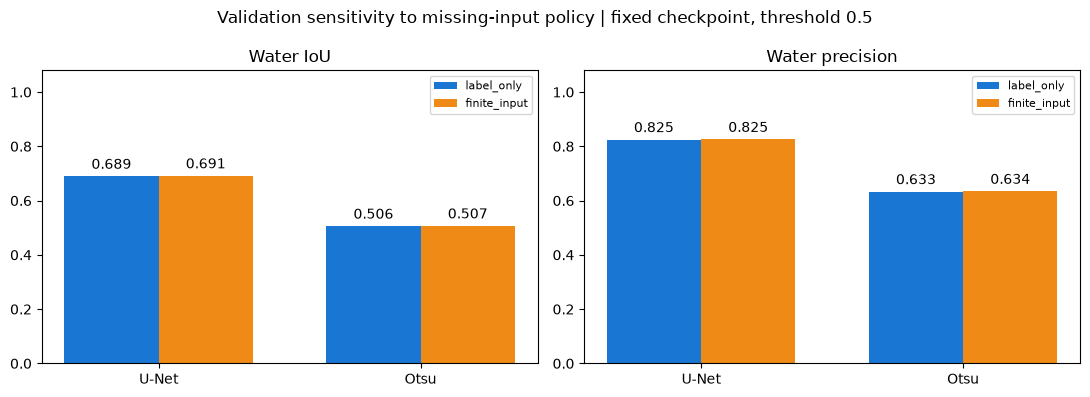

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ["iou_water", "precision"], ["Water IoU", "Water precision"]):
    positions=np.arange(2)
    for offset, policy, colour in [(-0.18, "label_only", "#1976d2"), (0.18, "finite_input", "#ef8a17")]:
        values=[report["results"][f"{method}_{policy}"][metric] for method in ["unet", "otsu"]]
        bars=ax.bar(positions+offset,values,width=0.36,color=colour,label=policy)
        ax.bar_label(bars,fmt="%.3f",padding=3)
    ax.set_xticks(positions,["U-Net", "Otsu"])
    ax.set_ylim(0,1.08);ax.set_title(title);ax.legend(fontsize=8)
fig.suptitle("Validation sensitivity to missing-input policy | fixed checkpoint, threshold 0.5")
fig.tight_layout()
fig.savefig(out / "input_policy_comparison.png",dpi=150,bbox_inches="tight")
plt.show();plt.close(fig)


## Visual inspection
Lowest, middle-ranked and highest IoU among chips with labelled water. Rankings describe diagnostic extremes, not representative samples.

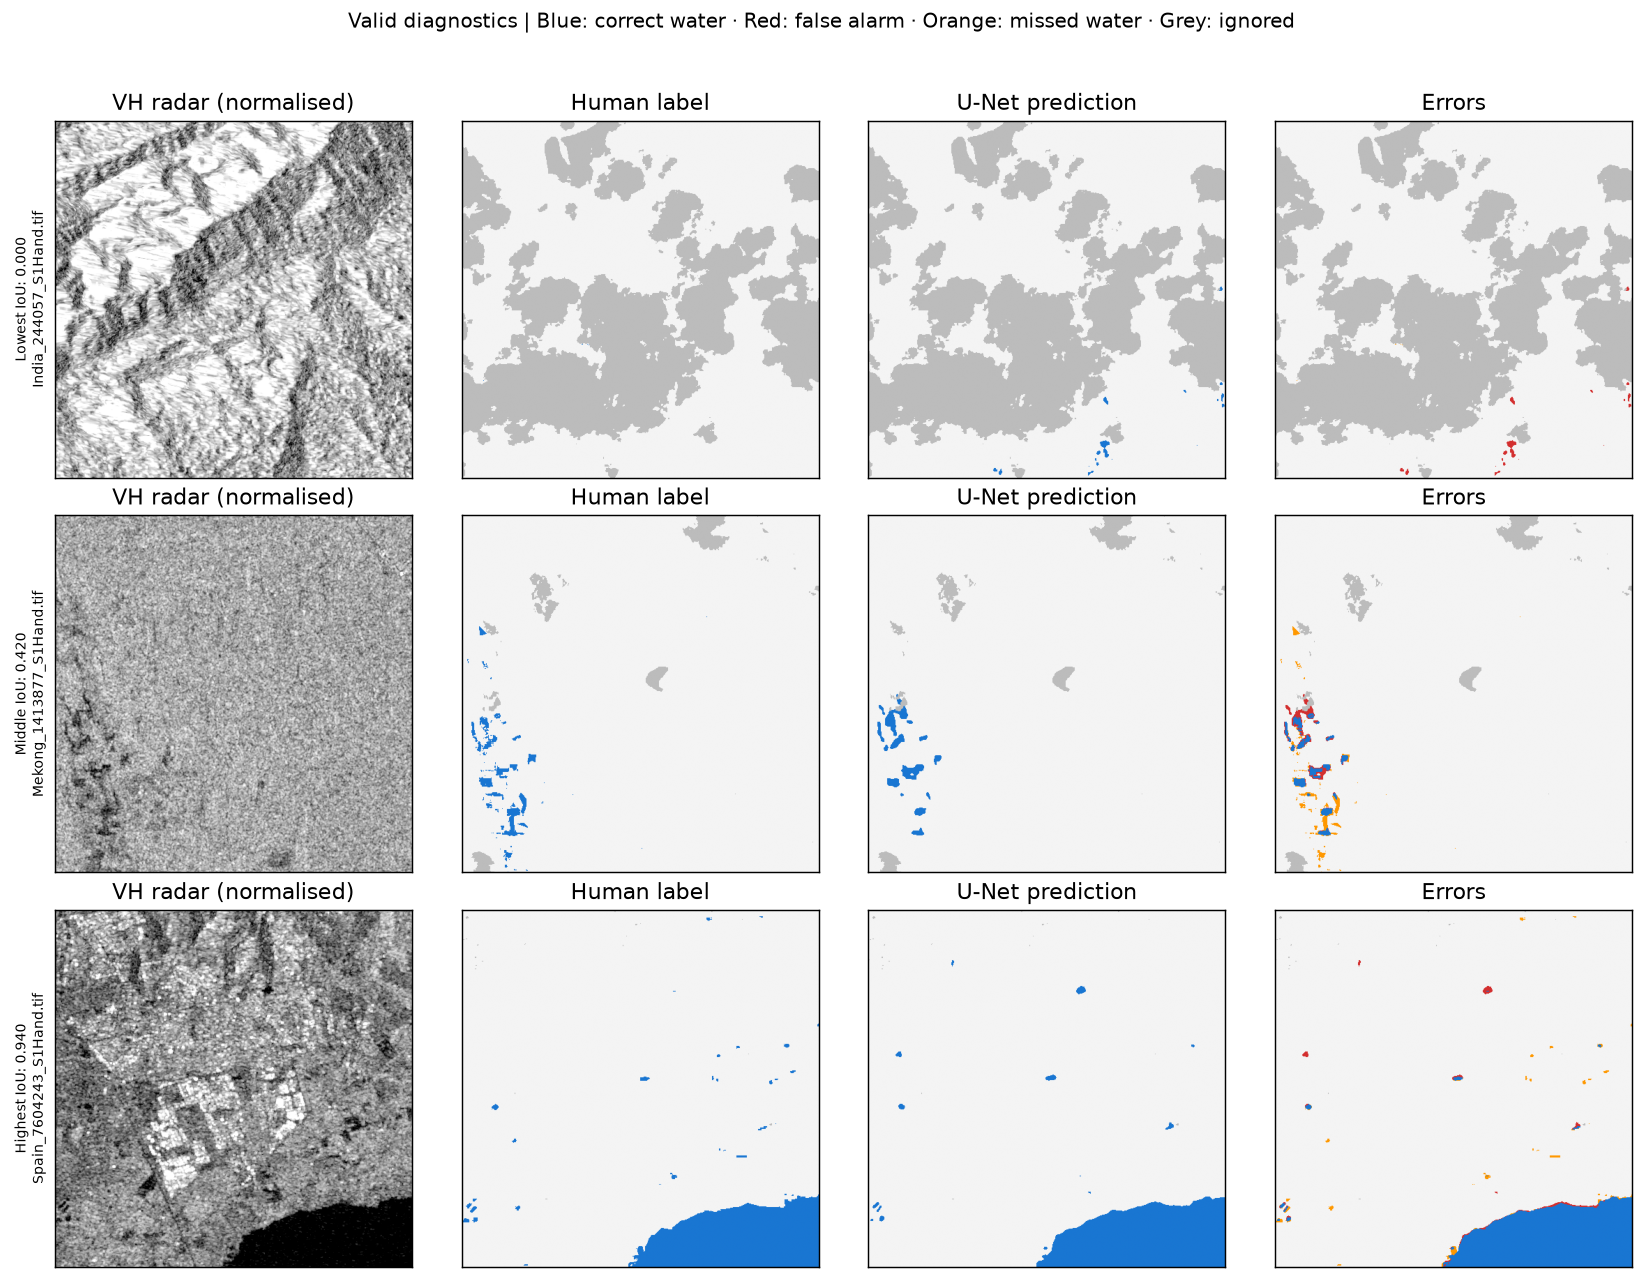

In [4]:
for split in ["valid"]:
    ds = Sen1Floods11(root, split)
    # Exclude chips without labelled water from example ranking; retain all in CSV.
    ranked = sorted([r for r in rows if r["split"] == split and r["water_pixels"] > 0],
                    key=lambda r: (r["water_iou"], r["chip"]))
    chosen = [ranked[0], ranked[len(ranked)//2], ranked[-1]]
    fig, axes = plt.subplots(3, 4, figsize=(13, 10))
    for row_idx, (tag, record) in enumerate(zip(["Lowest", "Middle", "Highest"], chosen)):
        x, y = ds[record["index"]]
        y = y.numpy()
        valid = y != -1
        with torch.inference_mode():
            pred = (model(x.unsqueeze(0)).sigmoid()[0, 0] > 0.5).numpy()
        errors = np.zeros_like(y)
        errors[~valid] = 4
        errors[valid & pred & (y == 1)] = 1
        errors[valid & pred & (y == 0)] = 2
        errors[valid & ~pred & (y == 1)] = 3
        masked_pred = np.where(valid, pred.astype(int), -1)
        axes[row_idx, 0].imshow(x[1], cmap="gray", vmin=-2, vmax=2)
        axes[row_idx, 1].imshow(y, cmap=ListedColormap(["#bcbcbc", "#f4f4f4", "#1976d2"]), vmin=-1, vmax=1)
        axes[row_idx, 2].imshow(masked_pred, cmap=ListedColormap(["#bcbcbc", "#f4f4f4", "#1976d2"]), vmin=-1, vmax=1)
        axes[row_idx, 3].imshow(errors, cmap=ListedColormap(["#f4f4f4", "#1976d2", "#d32f2f", "#ff9800", "#bcbcbc"]), vmin=0, vmax=4)
        for ax, title in zip(axes[row_idx], ["VH radar (normalised)", "Human label", "U-Net prediction", "Errors"]):
            ax.set_title(title)
            ax.set_xticks([]); ax.set_yticks([])
        axes[row_idx, 0].set_ylabel(f"{tag} IoU: {record['water_iou']:.3f}\n{record['chip']}", fontsize=8)
    fig.suptitle(f"{split.title()} diagnostics | Blue: correct water · Red: false alarm · Orange: missed water · Grey: ignored", fontsize=11)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(out / f"{split}_examples.png", dpi=130, bbox_inches="tight")
    from IPython.display import display, Image
    display(Image(filename=str(out / f"{split}_examples.png")))
    plt.close(fig)


## Interpretation

At threshold 0.5, validation precision is **82.46%** and recall **80.79%**. Excluding non-finite input pixels changes water IoU from **0.6894** to **0.6912**. Missing inputs affect only about **0.10%** of valid label pixels, so this policy has a small aggregate effect here.

Keep the original published protocol explicit. A threshold sweep on validation is a possible next experiment; any selected threshold must be saved as part of the model configuration. Validation used for selection cannot serve as independent evidence of final performance. See the saved audit report for caveats and the small discrepancy with logged mixed-precision validation results.